# 6. First OD solution

> Estimate the OSIRIS-REx trajectory from the week of simulated tracking with a batch square-root information filter, then inspect the solution: convergence, residuals, uncertainty, and errors against the truth.
>
> ⏱ ~15 min &nbsp;·&nbsp; **Prereqs:** [4. The filter's dynamics model](04_filter_dynamics.ipynb), [5. The filter's measurement model](05_filter_measurements.ipynb) &nbsp;·&nbsp; **Uses:** [`scenario.py`](scenario.py), `outputs/02_truth_dynamics/truth.bsp`, `outputs/03_tracking_data/*.json` &nbsp;·&nbsp; **Produces:** `outputs/06_first_od_solution/solution.json` &nbsp;·&nbsp; **Next:** [7. Sequential filtering & process noise](07_sequential_filtering.ipynb)

Chapters [4](04_filter_dynamics.ipynb) and [5](05_filter_measurements.ipynb) built the two halves of the problem: a reference trajectory with its STM and a-priori covariance, and the measurement models with their residuals and partials. A batch filter combines them: it maps every observation to the epoch $t_0$ through $\tilde H_k \Phi(t_k, t_0)$, solves the weighted least-squares problem for $\delta x_0$, and iterates until the reference stops changing.

## Setup

The objects built in chapters 1–5 (epochs, spacecraft, stations, measurement models, the a-priori state and covariance, and the filter's propagator) are collected in [`scenario.py`](scenario.py), so this chapter imports them instead of rebuilding them. The setup cell then loads what earlier chapters wrote to disk: the truth trajectory (chapter 2), used only to evaluate the solution, and the tracking data (chapter 3). `MeasurementSpec.from_models` pairs each measurement model with its observations, as in [chapter 5](05_filter_measurements.ipynb).

**Starting here?** This chapter reads the outputs of chapters [2](02_truth_dynamics.ipynb) and [3](03_tracking_data.ipynb). Run `python prepare.py 06` from `tutorials/v2/` to generate them (about 15 s).

In [1]:
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scarabaeus as scb

from scenario import (
    minute, day, J2000, sun,      # units, frame, central body
    epochs, orex, reference,      # tracking arc; truth and filter spacecraft (ch. 1, 4)
    models, TRACKING_DIR,         # range and range-rate from DSS-14/43/63 (ch. 3)
    r_apriori, v_apriori, P0,     # a-priori state and covariance (ch. 4)
    reference_propagator,         # the filter's dynamics model (ch. 4)
)

out = Path("outputs/06_first_od_solution")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)

# Starting here? `python prepare.py 06` creates the outputs of chapters 2 and 3.
scb.SpiceManager.load_kernel("outputs/02_truth_dynamics/truth.bsp")  # truth (ch. 2)
tracking = scb.MeasurementSpec.from_models(                              # tracking data (ch. 3, 5)
    models,
    [model.observed_measurements(f"{TRACKING_DIR}/{model.name.replace(' ', '_')}.json", units=model.sigma.units)
     for model in models],
)

## 1. Filter settings

`FilterSettings` collects everything about the estimation problem that is not the dynamics or the data:

<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> 
</div>

| Setting | Purpose | Chapter |
|---|---|---|
| `initial_covariance` | a-priori covariance $P_0$ | [4](04_filter_dynamics.ipynb) |
| `initial_deviation` | a-priori deviation $\bar x_0$ (default zero) | [4](04_filter_dynamics.ipynb) |
| `process_noise` | stochastic acceleration model (`ProcessNoiseSettings`) | [7](07_sequential_filtering.ipynb) |
| `measurement_sigmas` | per-dataset σ overrides | ? |
| `covariance_analysis` | covariance-only run, no state update | [7](07_sequential_filtering.ipynb) |
| `editing_method`, `editing_datasets`, `editing_kwargs` | measurement editing (outlier rejection) | [9](09_real_dsn_data.ipynb) |
| `output` | what the solution stores (`OutputSettings`) | |

`OutputSettings` controls the stored quantities. Residuals, the covariance history and the state deviation history are kept by default; debugging quantities (Kalman gains, innovation covariances, NIS) are off. Free-form `metadata` travels with the solution.

In [2]:
settings = scb.FilterSettings(
    initial_covariance=P0,
    output=scb.OutputSettings(
        metadata={"scenario": "OSIRIS-REx approach, 2018-06-01 to 06-08", "chapter": 6}
    ),
)

## 2. The batch filter

Scarabaeus has two batch filters with the same interface:

- `LSB`: least-squares batch, solving the normal equations $\left(P_0^{-1} + \sum_k H_k^T R_k^{-1} H_k\right)\delta x_0 = \sum_k H_k^T R_k^{-1} y_k$, with $H_k = \tilde H_k \Phi(t_k, t_0)$;
- `SRIFB`: batch square-root information filter, which solves the same problem with orthogonal (Householder) transformations on the square root of the information matrix, avoiding the loss of precision of forming $H^T R^{-1} H$ explicitly.

We use `SRIFB`. The constructor takes the reference propagator ([chapter 4](04_filter_dynamics.ipynb)), the `MeasurementSpec` ([chapter 5](05_filter_measurements.ipynb)) and the settings, propagates the reference, and evaluates the measurements on it. `reference_propagator()` builds the propagator of [chapter 4](04_filter_dynamics.ipynb) from the a-priori state. The reference is written to SPK as `reference.bsp`, then `reference_it2.bsp` and so on, one file per iteration.

## 3. Iterating to convergence

`fit()` solves for $\delta x_0$, re-propagates the reference from $x^*_0 + \delta x_0$, re-evaluates the residuals and partials, and repeats until a convergence test passes or `max_iterations` is reached. It returns the solution, the number of iterations, and whether it converged.

The same cell saves the solution, which section 5 opens.

In [3]:
%%capture fit_log
# 🔵 TODO: remove %%capture once the measurement models stop printing progress (~150 kB per fit)
srifb = scb.SRIFB(propagator=reference_propagator(), measurements=tracking, settings=settings,
                  traj_name="reference.bsp", traj_dir=str(out), verbose=False)
solution, n_iterations, converged = srifb.fit(max_iterations=10, convergence_threshold=1e-5, verbose=False)
solution.save(out / "solution.json")

In [4]:
print(f"Converged: {converged} after {n_iterations} iterations")

Converged: True after 2 iterations


`fit()` has two convergence tests. The deviation test is the RMS of the six components of $\delta x_0$ in km and km/s, so the threshold of $10^{-5}$ accepts a position correction of up to about 2.5 cm ($\sqrt 6 \times 10^{-5}$ km). The cost test is the relative change of the weighted cost $J = \sum (r/\sigma)^2$ of the post-fit residuals, divided by their number (`convergence_threshold_cost`, default $10^{-3}$). With the default `convergence_criterion="any"`, either test ends the iterations; `"deviation"`, `"cost"` and `"both"` select one or require both. Here the cost test ends the fit after the second iteration: the cost changes by less than $10^{-6}$, while the deviation test, at an RMS of $3 \times 10^{-5}$, would have asked for a third. The saved solution records both tests under `metadata.convergence` (section 5).

## 4. Solution statistics

`print_stats` summarizes the solution: the post-fit χ² test and the formal 1σ uncertainties at the first and last measurement epochs.

In [5]:
solution.print_stats()

ORBIT DETERMINATION SOLUTION STATISTICS

Solution Overview:
  Number of epochs:        270
  Number of states:        6
  Covariance analysis:     False

Chi-Squared Test:
  Chi-squared value:       600.0712
  Degrees of freedom:      626
  Normalized chi-squared:  0.9586
  Status:                  Filter appears well-tuned

Covariance Information:
  Initial position uncertainty (1σ):
    X: 7.540777e-01 km
    Y: 9.212231e-01 km
    Z: 1.017740e+00 km
    RSS: 1.566231e+00 km
  Final position uncertainty (1σ):
    X: 8.402855e-01 km
    Y: 9.462019e-01 km
    Z: 1.125326e+00 km
    RSS: 1.693439e+00 km
  Initial velocity uncertainty (1σ):
    VX: 3.017435e-07 km/s
    VY: 1.175928e-06 km/s
    VZ: 9.514246e-07 km/s
    RSS: 1.542422e-06 km/s
  Final velocity uncertainty (1σ):
    VX: 2.921283e-07 km/s
    VY: 1.175687e-06 km/s
    VZ: 9.518281e-07 km/s
    RSS: 1.540635e-06 km/s


A normalized χ² close to 1 means the post-fit residuals are consistent with the measurement σ, as expected when the filter's models match those that generated the data.

## 5. Saving the solution

The fit cell saved the solution with `save`, which writes it, including every iteration, to a single JSON file:

In [6]:
with open(out / "solution.json") as f:
    record = json.load(f)

print("top-level keys:", list(record))
print("metadata:      ", list(record["metadata"]))
print("per iteration: ", list(record["final"]))

top-level keys: ['metadata', 'iter_1', 'iter_2', 'final']
metadata:       ['n_states', 'is_covariance_analysis', 'n_iterations', 'frame', 'units', 'residual_columns', 'epoch_system', 'epoch_units', 'covariance_storage', 'state_components', 'state_labels', 'apriori', 'convergence', 'provenance', 'scenario', 'chapter']
per iteration:  ['timestamps', 'timeline_epochs', 'deviation_estimated', 'deviation_cumulative', 'state_estimated', 'covariance_full', 'prefits', 'postfits', 'timestamps_alignment', 'epoch_solution']


The metadata describes the state (components, frame, units, labels), the a-priori state and covariance, the convergence test and the provenance; the residual entries are `[residual, σ, epoch]` (`residual_columns`). The file is self-contained, so the iteration history can be read back from it. For each iteration: the size of the correction (at the first measurement epoch) and the RMS of the normalized pre-fit residuals of that iteration's reference:

In [7]:
print(f"{'iteration':>9s} {'|δr| [km]':>12s} {'|δv| [mm/s]':>12s} {'pre-fit RMS/σ':>14s}")
for k in range(1, record["metadata"]["n_iterations"] + 1):
    iteration = record[f"iter_{k}"]
    dx = np.array(iteration["deviation_estimated"][0])
    z = np.array([r / s for dataset in iteration["prefits"].values() for r, s, _ in dataset])
    print(f"{k:9d} {np.linalg.norm(dx[:3]):12.3e} {np.linalg.norm(dx[3:]) * 1e6:12.3e} {np.sqrt(np.mean(z**2)):14.2f}")

iteration    |δr| [km]  |δv| [mm/s]  pre-fit RMS/σ
        1    1.741e+01    1.754e+01        7890.57
        2    7.406e-05    7.491e-05           0.97


The first iteration removes almost all of the 17 km / 1.7 cm/s a-priori error: as [chapter 4](04_filter_dynamics.ipynb) showed, the problem is nearly linear at this scale. The second iteration corrects the remaining linearization error of a few centimeters, which no longer changes the cost, so the fit stops there. The pre-fit residuals fall from thousands of σ to the noise level.

## 6. Residuals

Because the file is self-contained, `Plotting.plot_residuals_json` can plot residuals from it directly: one panel per dataset, against each observation's epoch, with the RMS and number of points in the legend. With `weighted=True` the residuals are divided by σ. First, the pre-fit residuals of iteration 1, on the a-priori reference:

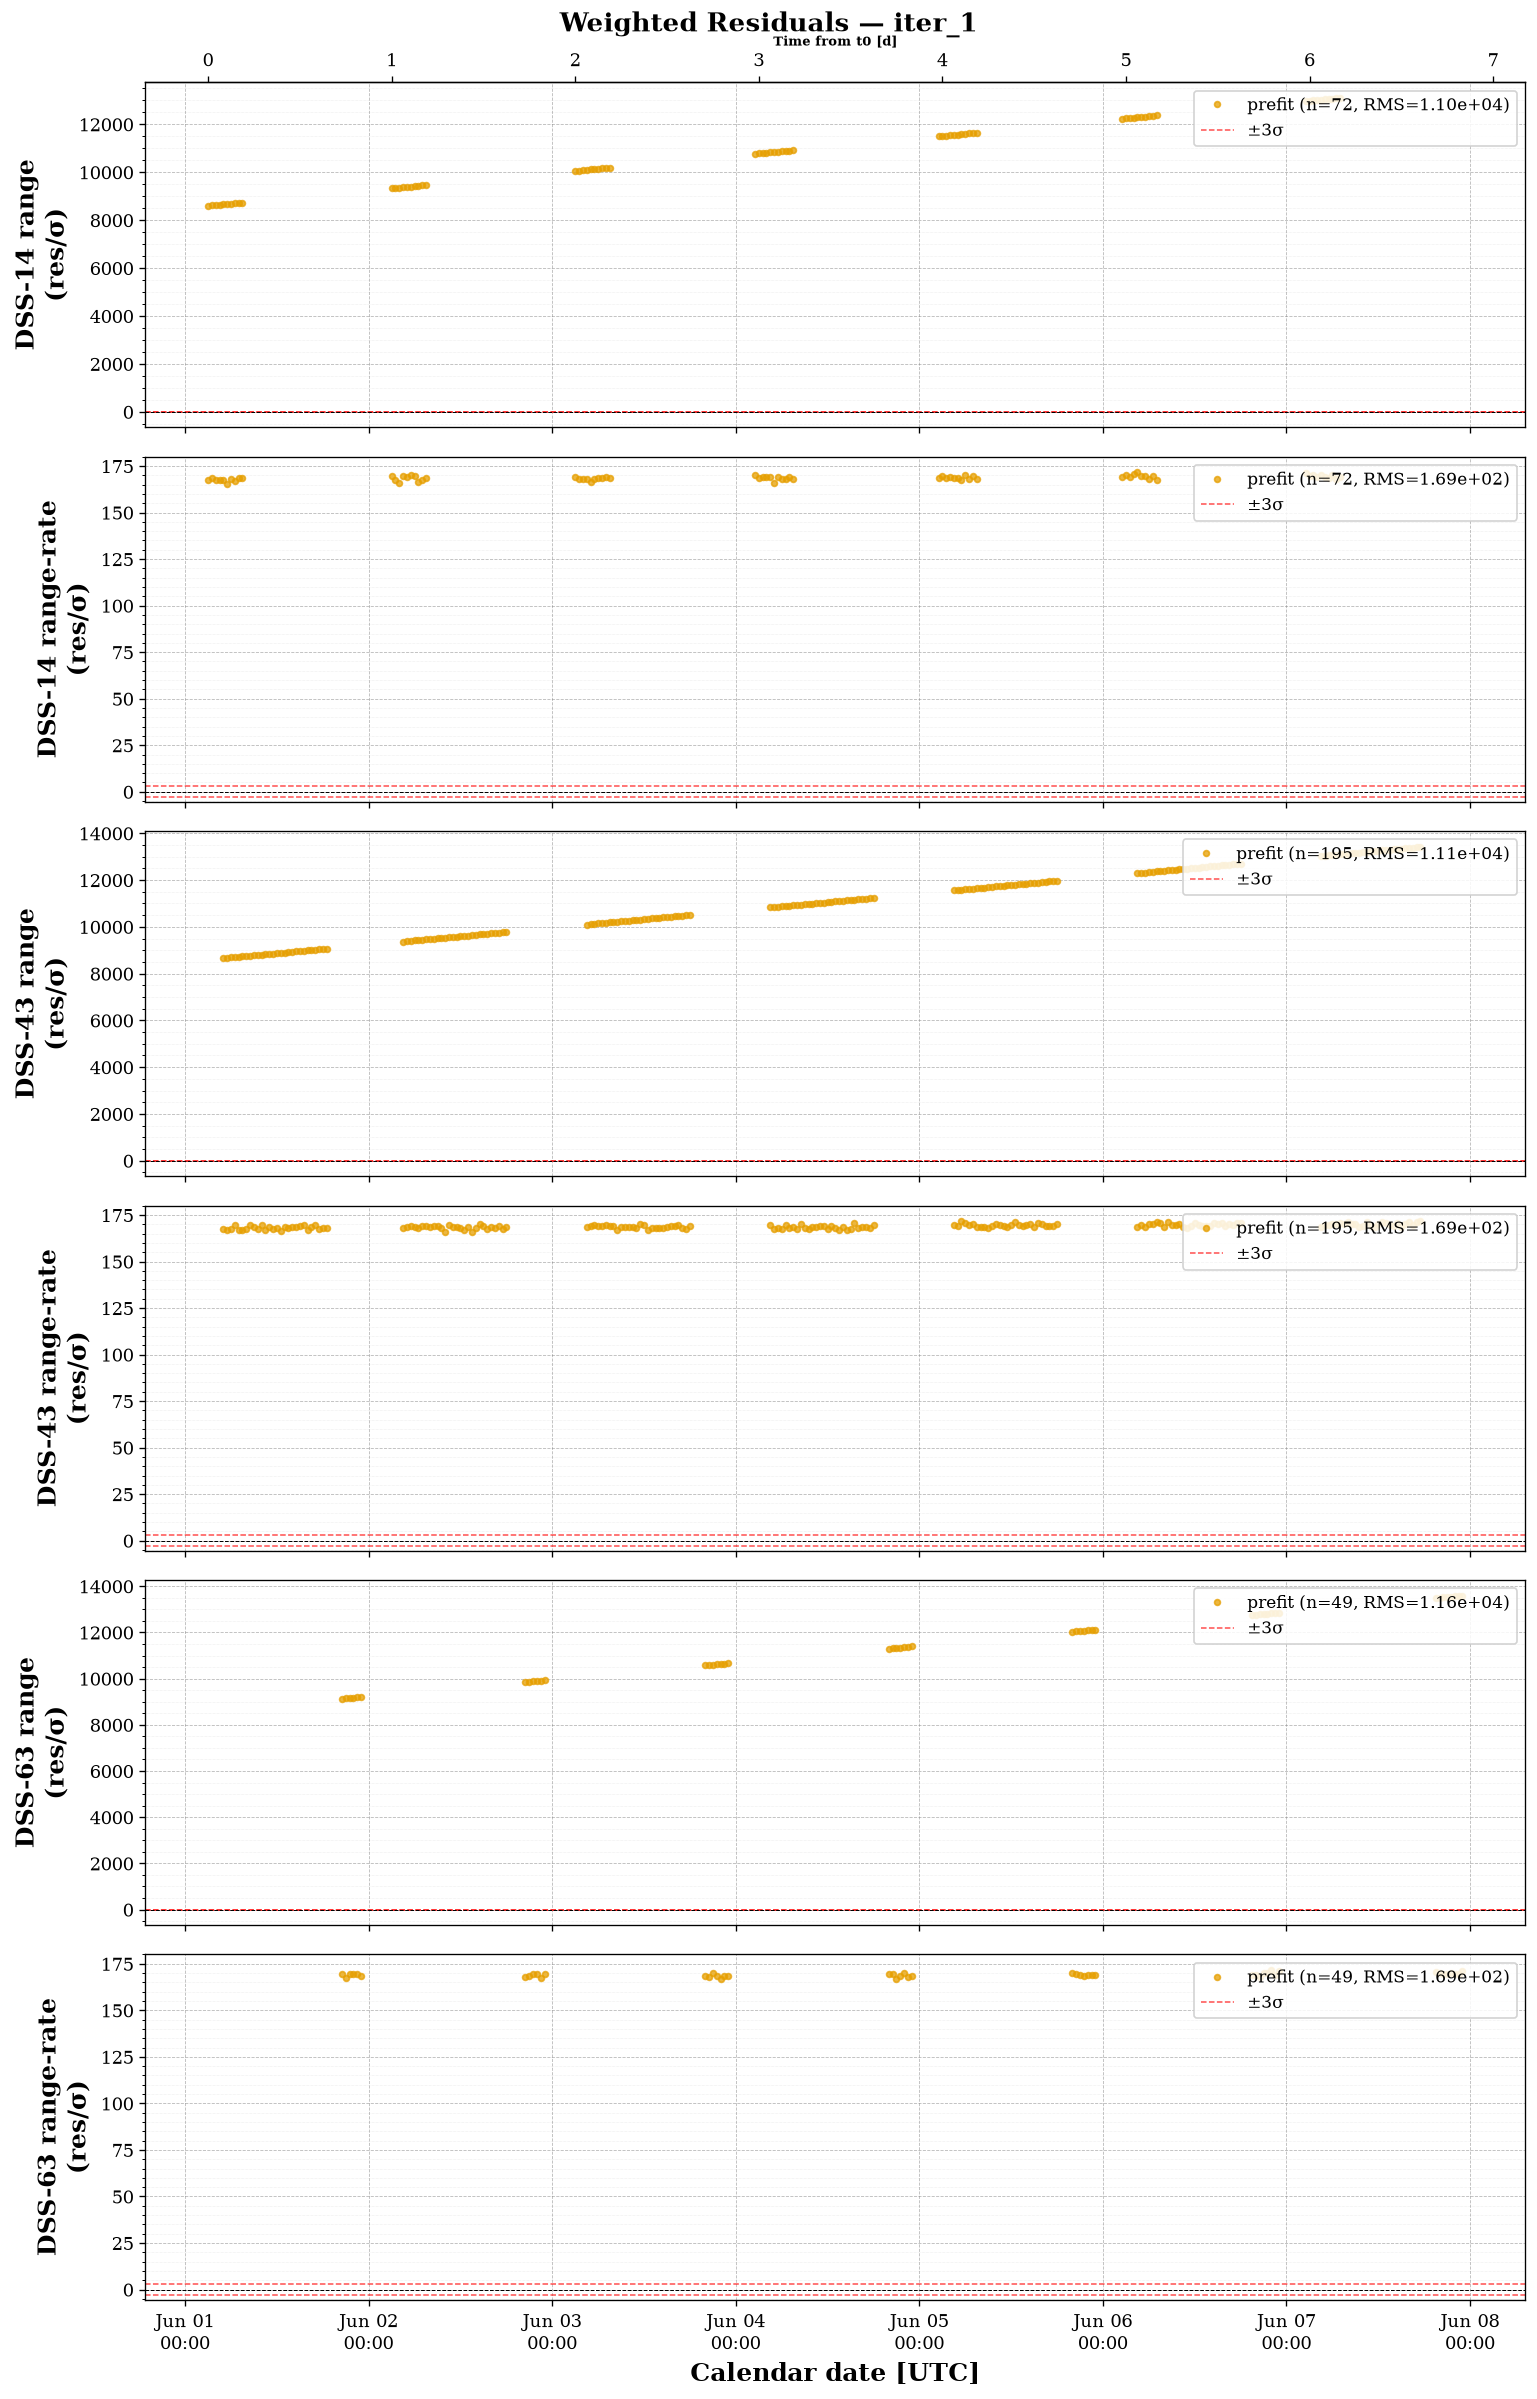

In [8]:
scb.Plotting.plot_residuals_json(out / "solution.json", iteration="iter_1", kind="prefit", weighted=True, time_unit="day");

Each data type sees the a-priori error in its own way. Range-rate measures the line-of-sight velocity, so the 1 cm/s-per-axis velocity error shows up as a nearly constant offset of about 170σ (the projection of a 1.7 cm/s error on the line of sight, against σ = 0.1 mm/s). Range measures the distance, which that same velocity error changes by about 1.5 km per day: the range residuals start near 9,000σ and climb steadily through the week.

The post-fit residuals of the converged solution:

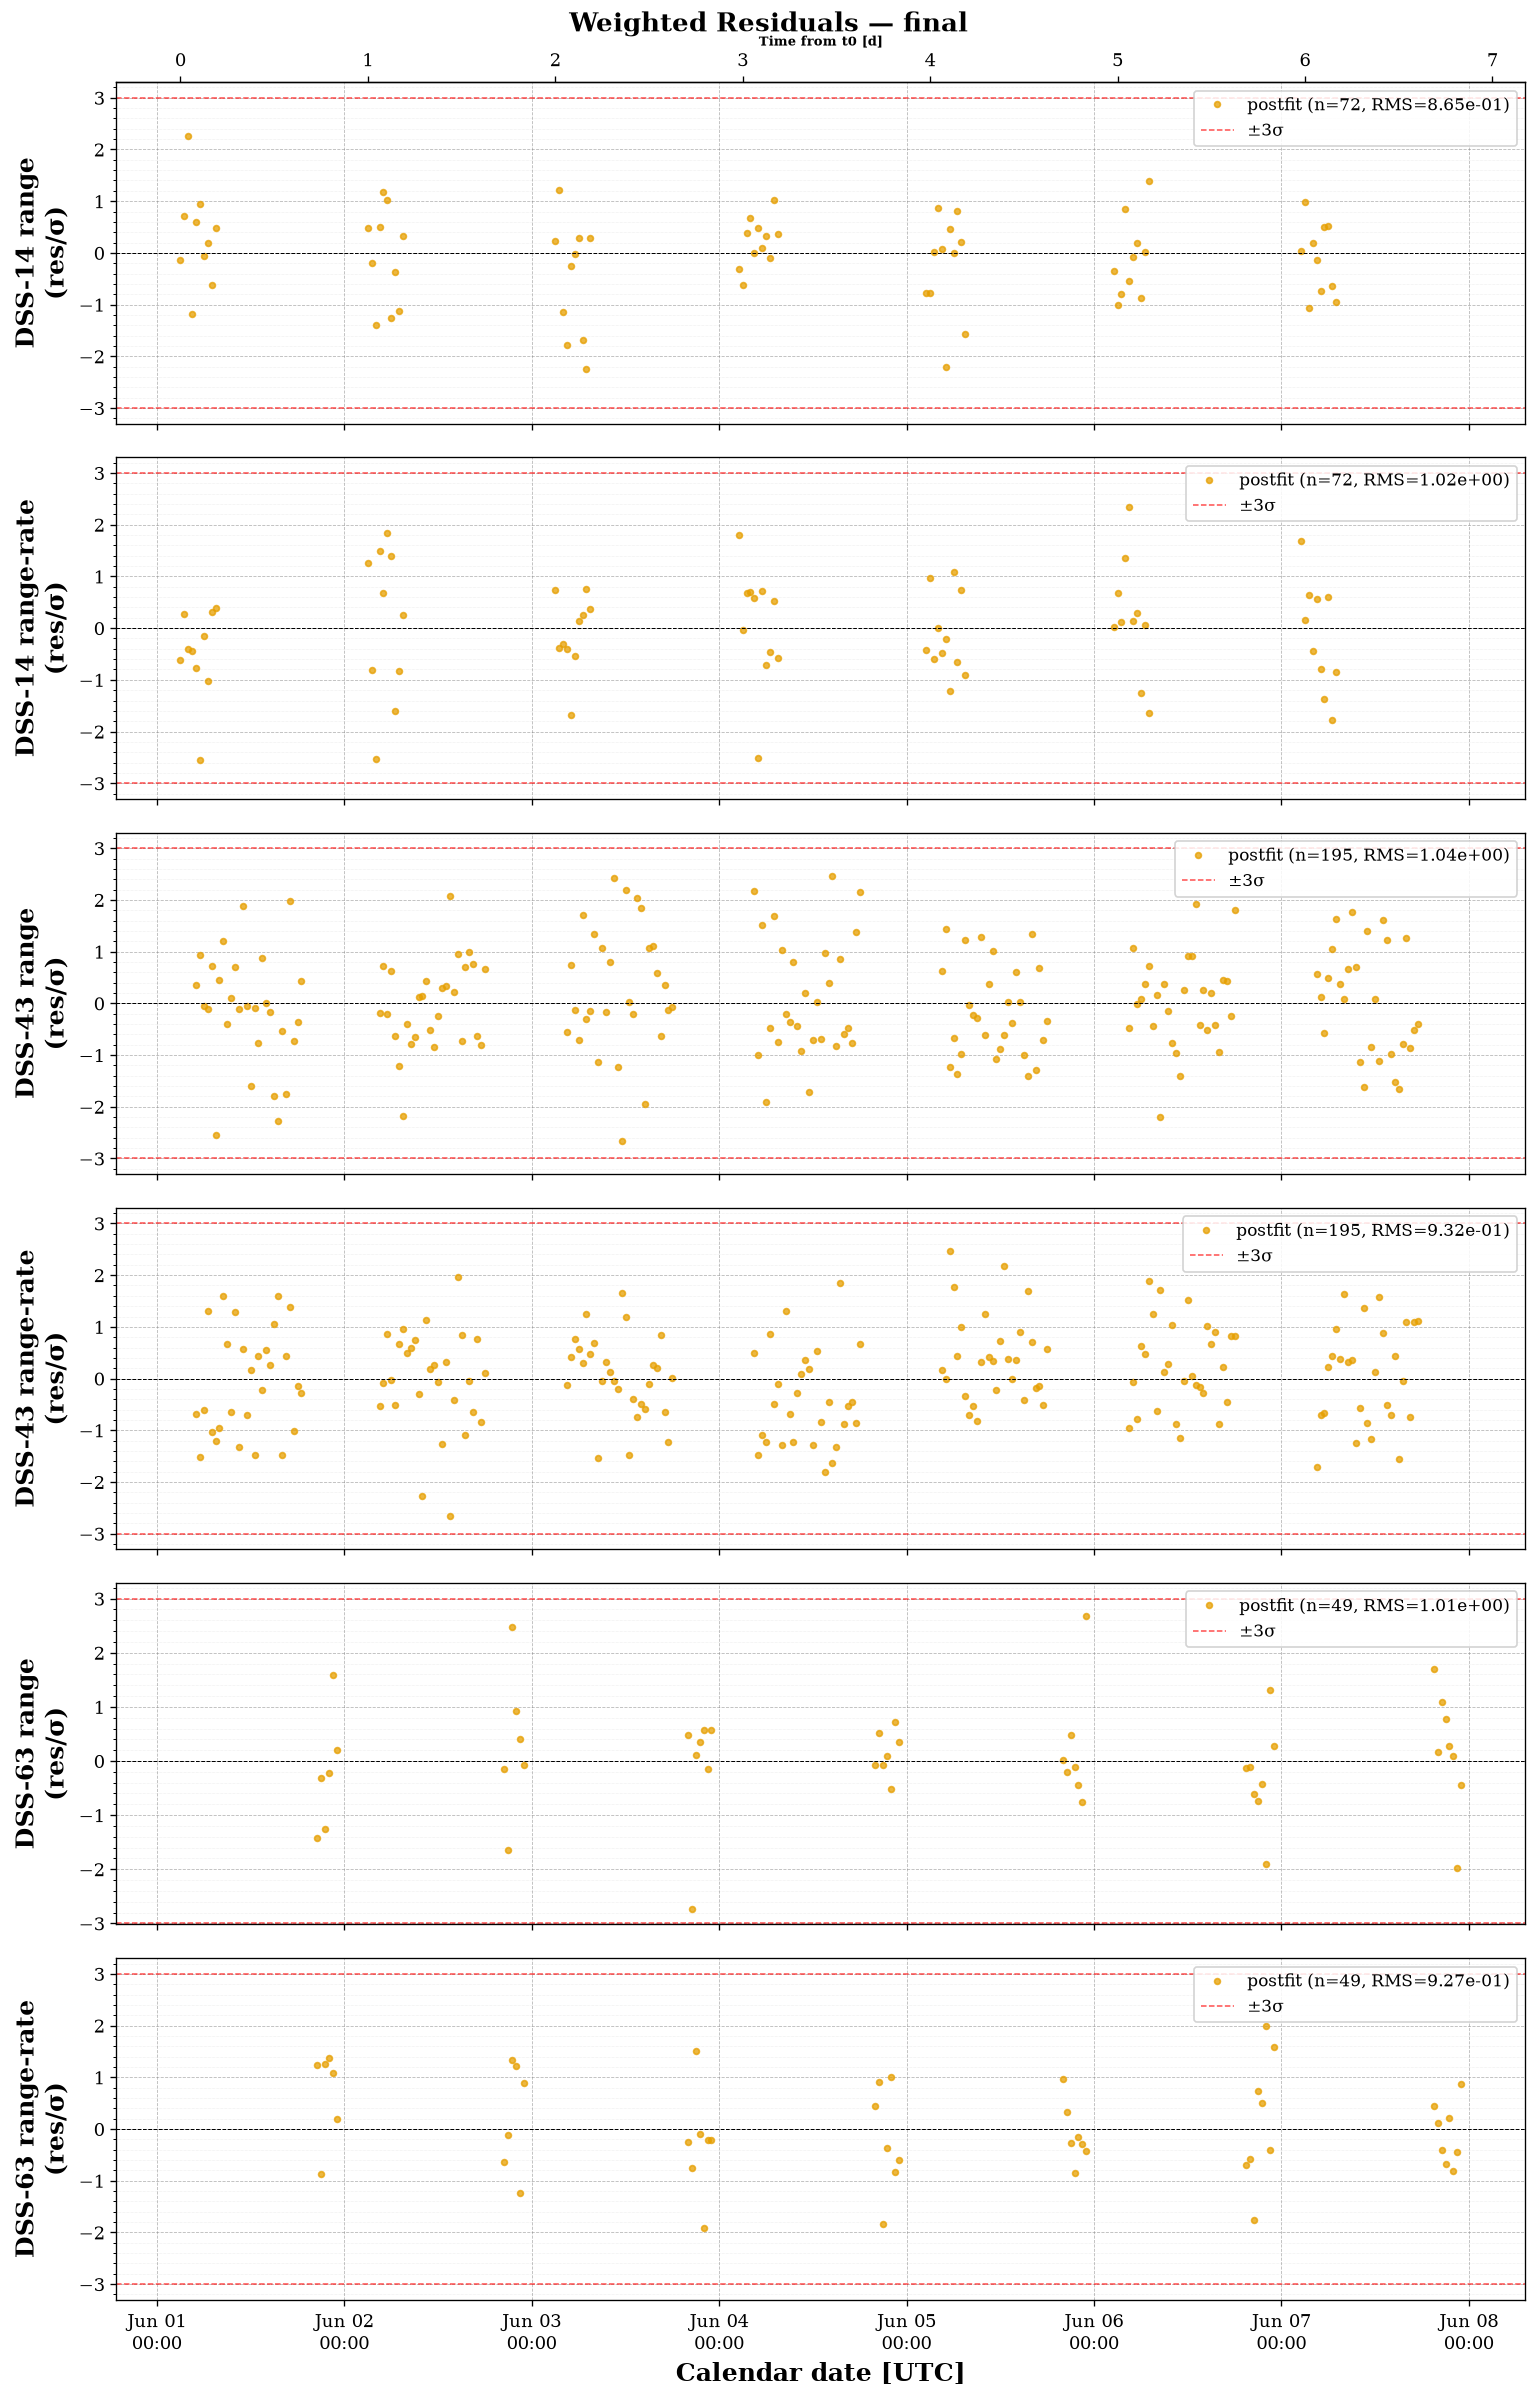

In [9]:
scb.Plotting.plot_residuals_json(out / "solution.json", iteration="final", kind="postfit", weighted=True, time_unit="day");

Every dataset is white noise within ±3σ, with an RMS close to 1: the filter's models match those that generated the data, and nothing systematic is left. The point counts also summarize the tracking schedule of [chapter 3](03_tracking_data.ipynb): DSS-43 (Canberra) provides most of the data.

## 7. The estimate

`propagate_state_covariance` returns the estimated state and its covariance at any epochs, both mapped from the solution through the dynamics. At $t_0$, against the truth and the a-priori:

In [10]:
x_est0, P_est0 = solution.propagate_state_covariance(epochs[0:1])[0]
x_true0 = orex.get_state(epochs[0], reference_frame="J2000", origin="SUN").quantity.values

error_apriori = np.concatenate([r_apriori.values, v_apriori.values]) - x_true0
error_estimate = x_est0.values0.values - x_true0
sigma_estimate = np.sqrt(np.diag(P_est0))

labels = ["x [km]", "y [km]", "z [km]", "vx [mm/s]", "vy [mm/s]", "vz [mm/s]"]
scale = [1, 1, 1, 1e6, 1e6, 1e6]
print(f"{'':10s} {'a-priori error':>15s} {'estimate error':>15s} {'1-sigma':>8s} {'error/sigma':>8s}")
for i, label in enumerate(labels):
    print(
        f"{label:10s} {error_apriori[i] * scale[i]:15.3f} {error_estimate[i] * scale[i]:15.3f}"
        f" {sigma_estimate[i] * scale[i]:8.3f} {error_estimate[i] / sigma_estimate[i]:+8.2f}"
    )

            a-priori error  estimate error  1-sigma error/sigma
x [km]              10.000          -0.431    0.753    -0.57
y [km]              10.000           0.470    0.926    +0.51
z [km]              10.000           0.158    1.018    +0.15
vx [mm/s]           10.000          -0.084    0.302    -0.28
vy [mm/s]           10.000          -1.157    1.176    -0.98
vz [mm/s]           10.000           0.980    0.951    +1.03


The estimation error is within about 1σ in every component: the formal covariance is a realistic description of the actual error.

## 8. Errors over the arc

`Plotting.plot_state_errors` makes the same comparison along the whole arc, with 1, 2 and 3σ bands from the solution covariance. It takes the truth as a `Trajectory`; built from a body, a `Trajectory` reads its states from the kernel pool, here the truth SPK of [chapter 2](02_truth_dynamics.ipynb):

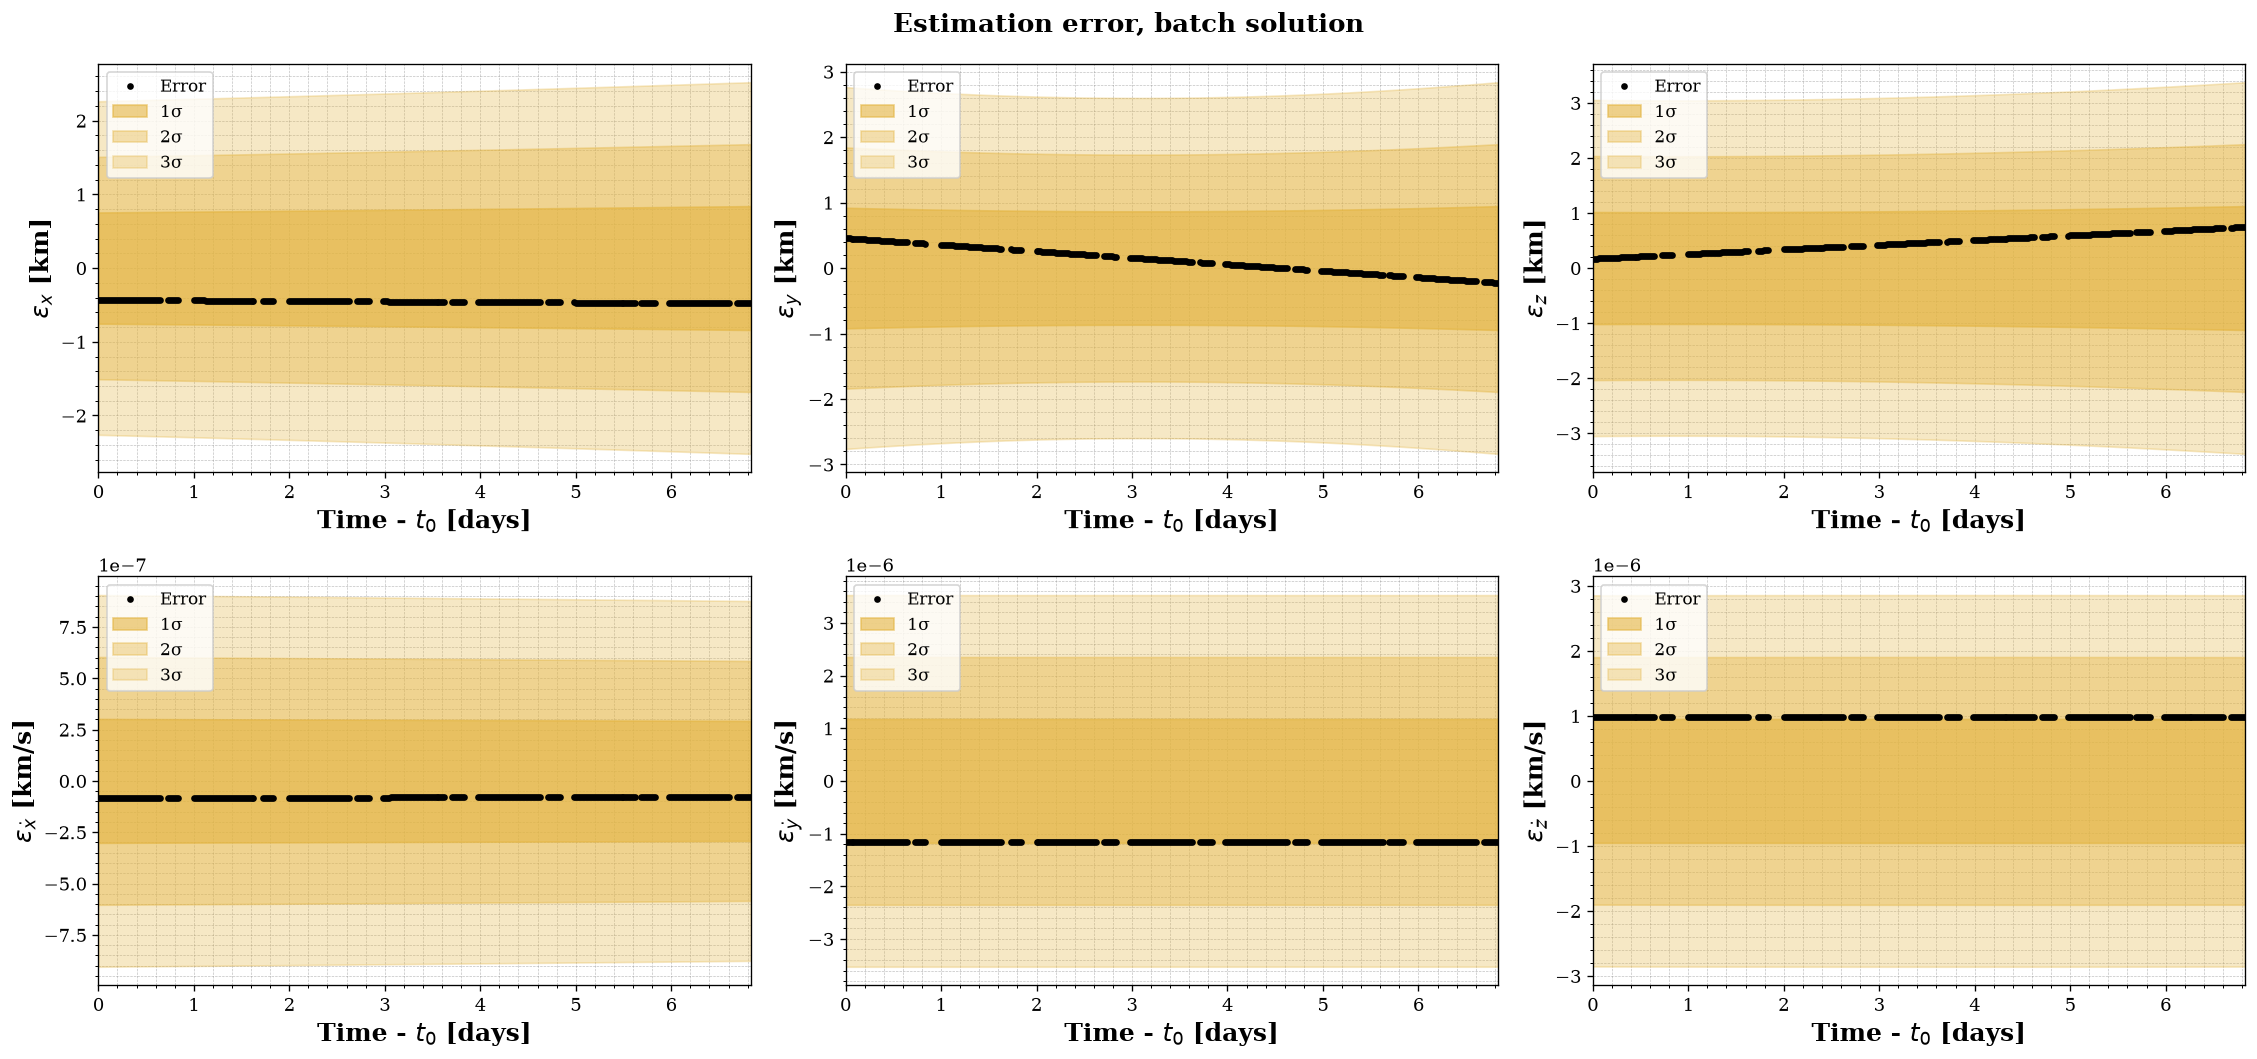

In [11]:
truth = scb.Trajectory(ref_frame=J2000, origin=sun, body=orex)
t_est = scb.EpochArray(solution.timestamps, sys="TDB")  # the measurement epochs

scb.Plotting.plot_state_errors(solution, truth, t_est, n_sigma=3, title="Estimation error, batch solution");

Over one week of a heliocentric orbit, gravity barely changes an error: the velocity error stays nearly constant and the position error grows linearly at that rate (e.g. $v_y \approx -1.2$ mm/s gives the −0.7 km drift in $y$). Without process noise, the whole curve is one initial-state error carried forward by the dynamics; its sign and size come from this noise realization, not a bias.

## 9. The shape of the uncertainty

A position uncertainty of about 1 km per axis may seem large for 2 m range data. The covariance is far from isotropic: two-way range measures the distance along the line of sight directly, while the plane-of-sky position is inferred only indirectly, through the dynamics and the diurnal range-rate signature ([chapter 3](03_tracking_data.ipynb)). Projecting the covariance at the end of the arc onto the Earth–spacecraft line of sight:

In [12]:
_, P_end = solution.propagate_state_covariance(epochs[-1:])[0]
los = reference.get_state(epochs[-1], reference_frame="J2000", origin="EARTH").quantity.values[:3]
u = los / np.linalg.norm(los)  # Earth-spacecraft direction

P_pos = P_end[:3, :3]
sigma_los = np.sqrt(u @ P_pos @ u)
sigma_total = np.sqrt(np.trace(P_pos))
print(f"1-sigma along the line of sight: {sigma_los * 1e3:.2f} m")
print(f"1-sigma in the plane of sky:     {np.sqrt(sigma_total**2 - sigma_los**2):.2f} km (RSS of the two transverse directions)")

1-sigma along the line of sight: 0.45 m
1-sigma in the plane of sky:     1.69 km (RSS of the two transverse directions)


The position is known to well under a meter along the line of sight and to about a kilometer across it. This geometry is typical of Earth-based radiometric tracking of a distant spacecraft, and it is the motivation for adding data types that measure the plane of sky directly, such as ΔDOR or optical navigation <div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> (see *Model catalogs: Measurement types*).
</div>

## 10. Predicting past the data

`propagate_state_covariance` is not limited to the data arc: past the last observation, the state and covariance it returns are a prediction. The truth of [chapter 2](02_truth_dynamics.ipynb) runs to June 11, three days past the tracking, so the prediction can be scored like the estimate in section 8: error against the truth, with the 3σ bounds the solution claims.

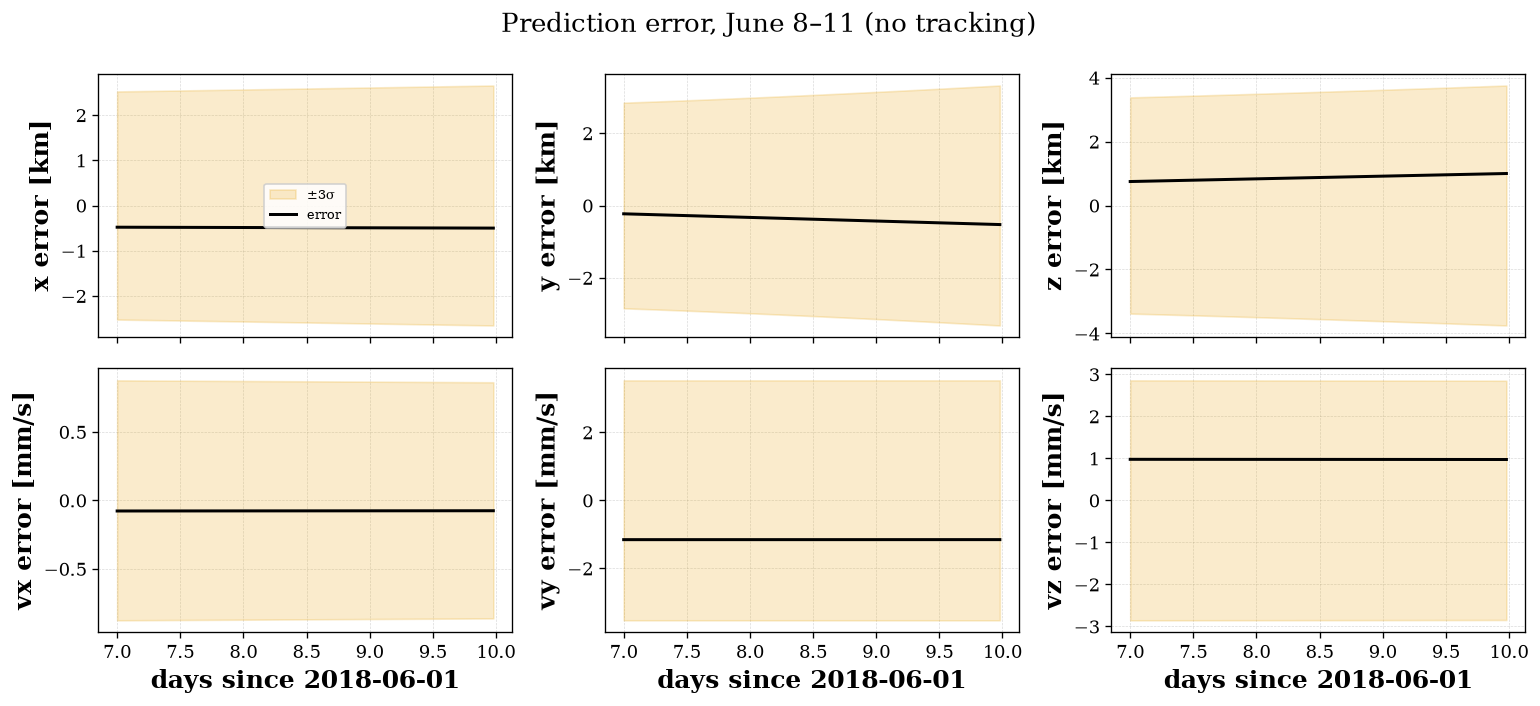

In [13]:
t_predict = scb.EpochArray.interval(
    scb.SpiceManager.utc2et("2018-06-08T00:00:00"),
    scb.SpiceManager.utc2et("2018-06-11T00:00:00"),
    dt=scb.ArrayWUnits(30, minute),
    sys="TDB",
)
predicted = solution.propagate_state_covariance(t_predict)

# TODO(draft): get_state takes one epoch at a time; replace the loop once it accepts an EpochArray
x_true = np.array([orex.get_state(t, reference_frame="J2000", origin="SUN").quantity.values for t in t_predict])
error = np.array([state.values0.values for state, _ in predicted]) - x_true
sigma3 = 3 * np.sqrt([np.diag(P) for _, P in predicted])
t_days = (t_predict - epochs[0]).convert_to(day).values

# 🔵 TODO: use Plotting.plot_state_errors once it accepts epochs past the data arc (scb_suggestions.md 6.74)
fig, ax = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for i, c in enumerate("xyz"):
    for row, k, scale, unit in [(0, i, 1, "km"), (1, 3 + i, 1e6, "mm/s")]:
        ax[row, i].fill_between(t_days, -sigma3[:, k] * scale, sigma3[:, k] * scale, color="C0", alpha=0.2, label="±3σ")
        ax[row, i].plot(t_days, error[:, k] * scale, "k", label="error")
        ax[row, i].set(ylabel=f"{'' if row == 0 else 'v'}{c} error [{unit}]")
        ax[row, i].grid(alpha=0.3)
    ax[1, i].set(xlabel="days since 2018-06-01")
ax[0, 0].legend(fontsize=8)
fig.suptitle("Prediction error, June 8–11 (no tracking)")
plt.tight_layout()

The prediction stays consistent for the whole three days: every error component remains well inside its 3σ bounds. It also behaves as section 8 described. The velocity error and its uncertainty are flat, because over a few days heliocentric gravity hardly couples a position error into velocity. Each position error keeps drifting at its velocity error (e.g. $v_y \approx -1.2$ mm/s, or −0.3 km over three days), and the position bounds widen slowly for the same reason.

Nothing changes at the end of the data. A batch solution is one state and covariance at $t_0$, mapped through the dynamics to any epoch, so without process noise there is no difference between an epoch inside the arc and one after it. Process noise ([chapter 7](07_sequential_filtering.ipynb)) is what makes the uncertainty grow once the tracking stops.

## 11. Switching the algorithm

The filters share one interface, so changing the estimator is a one-line change. One caveat: a filter updates the `Propagator` it is given in place (after `fit()` it holds the estimated state), so each filter needs its own propagator built from the a-priori state: a fresh call to `reference_propagator()`. `LSB` on the same inputs gives the same solution to within a few centimeters, the size of the last correction each filter accepts at convergence, and far below the 1σ uncertainty of about 1 km:

In [14]:
%%capture fit_log_lsb
lsb = scb.LSB(propagator=reference_propagator(), measurements=tracking, settings=settings,
              traj_name="reference_lsb.bsp", traj_dir=str(out), verbose=False)
solution_lsb, _, _ = lsb.fit(convergence_threshold=1e-5, verbose=False)

In [15]:
difference = solution_lsb.state_est[0] - solution.state_est[0]
print(f"LSB - SRIFB position: {np.linalg.norm(difference[:3]) * 1e6:.2f} mm")
print(f"LSB - SRIFB velocity: {np.linalg.norm(difference[3:]) * 1e9:.4f} mm/s")

LSB - SRIFB position: 41.58 mm
LSB - SRIFB velocity: 0.0800 mm/s


<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> `SolutionCloseness.between(solution, solution_lsb)` is the library's way to say how far apart two solutions are in σ, but it currently reports ~2σ for these two (the true Mahalanobis distance is ~1e-4): use it here once it handles heliocentric states (`scb_suggestions.md` 6.65).
</div>

[Chapter 7](07_sequential_filtering.ipynb) makes the same swap to the sequential filters, which process the observations one epoch at a time and allow process noise.

## Summary

| Concept | Scarabaeus API |
|---|---|
| Mission definition | `scenario.py` (the objects of chapters 1–5) |
| Measurement models with their data | `MeasurementSpec.from_models(models, observed)` |
| Estimation settings | `FilterSettings(initial_covariance=..., output=OutputSettings(...))` |
| Batch filters | `SRIFB(propagator, measurements, settings)`, `LSB(...)` |
| Iterating to convergence | `fit(max_iterations=..., convergence_threshold=...)` → `(solution, n_iterations, converged)` |
| Solution summary | `SolutionOD.print_stats()` |
| Saving | `SolutionOD.save(path)` (JSON with every iteration) |
| Residuals from a saved solution | `Plotting.plot_residuals_json(path, iteration=..., kind=..., weighted=True)` |
| Estimated state and covariance at any epoch, in or past the arc | `SolutionOD.propagate_state_covariance(epochs)` |
| Errors against a truth trajectory | `Trajectory(ref_frame, origin, body=...)`, `Plotting.plot_state_errors(solution, truth, epochs, n_sigma)` |

**Next:** [7. Sequential filtering & process noise](07_sequential_filtering.ipynb) processes the same data with `SRIF` and `LKF`, adds process noise, and compares the result with the batch solution.